# Lecture 14 Demos

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Demo 1: impulse response of second-order CT system

For the $\zeta \neq 1$ case, 
$$
 h(t) =  \frac{\omega_{n}}{2\sqrt{\zeta^{2} -1}} \left(e^{c_{+} t} -
   e^{c_{-}t}\right) u(t), \quad  \quad c_{\pm} = -\zeta \omega_{n} \pm \omega_n \sqrt{\zeta^{2}-1}
$$   

When $\zeta = 1$, 

$$
 h(t) = \omega_{n}^{2} t e^{-\omega_{n} t} u(t)
$$

In [2]:
def compute_impulse_response(ζ, ω_n):
    if ζ == 1:
        def impulse_response(t):            
            return (ω_n ** 2) * t * np.exp(-ω_n * t) 
        return impulse_response
    
    # ζ != 1 cases can be considered together
    if ζ < 1:
        ζ = ζ + 0j
    c_p = -ζ * ω_n + ω_n * np.sqrt(ζ ** 2 - 1)
    c_m = -ζ * ω_n - ω_n * np.sqrt(ζ ** 2 - 1)

    def impulse_response(t):
        return ω_n / (2 * np.sqrt(ζ ** 2 - 1)) * (np.exp(c_p * t) - np.exp(c_m * t))

    return impulse_response

In [3]:
times = np.linspace(0, 2, 1000)
ζ_values = [0.2, 0.4, 0.8, 1.0, 1.2, 1.4, 1.8]
ω_n = 10

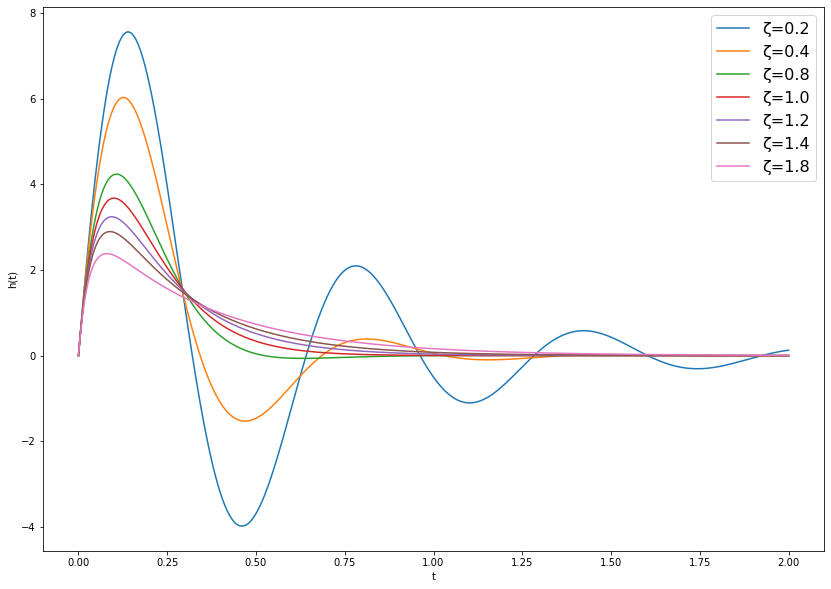

In [4]:
plt.figure(figsize=(14, 10))

for ζ in ζ_values:
    impulse_response = compute_impulse_response(ζ, ω_n)
    plt.plot(times, impulse_response(times).real, label=f"ζ={ζ}")
    
plt.ylabel("h(t)")
plt.xlabel("t")
plt.legend(fontsize=16)

## Demo 2: step response of second-order CT system

For the $\zeta \neq 1$ case, 
$$
 s(t) =  \left[1 + \frac{\omega_{n}}{2\sqrt{\zeta^{2} -1}} \left(\frac{e^{c_+ t}}{c_+} - \frac{e^{c_- t}}{c_-} \right) \right] u(t)
$$

When $\zeta = 1$, 

$$
 s(t) = \left(1 - e^{-\omega_{n}t} - \omega_n t e^{-\omega_{n} t}\right) u(t)
$$

In [5]:
def compute_step_response(ζ, ω_n):
    if ζ == 1:
        def step_response(t):            
            return 1 - np.exp(-ω_n * t) * (1 + ω_n * t)
        return step_response
    
    if ζ < 1:
        ζ = ζ + 0j
    c_p = -ζ * ω_n + ω_n * np.sqrt(ζ ** 2 - 1)
    c_m = -ζ * ω_n - ω_n * np.sqrt(ζ ** 2 - 1)

    def step_response(t):
        return 1 + (ω_n / (2 * np.sqrt(ζ ** 2 - 1))) * (np.exp(c_p * t)/c_p - np.exp(c_m * t)/c_m)

    return step_response

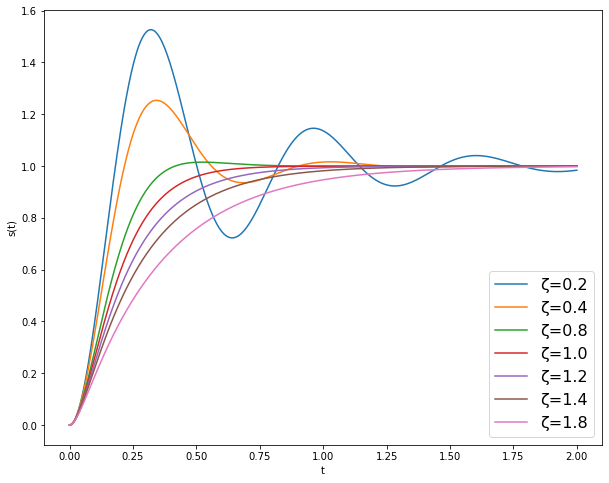

In [6]:
plt.figure(figsize=(10, 8))
for ζ in ζ_values:
    step_response = compute_step_response(ζ, ω_n)
    plt.plot(times, step_response(times).real, label=f"ζ={ζ}")
    
plt.ylabel("s(t)")
plt.xlabel("t")
plt.legend(fontsize=16)

## Demo 3: Bode plots

For the $\zeta \neq 1$ case, 
$$
 H(j\omega) = \frac{\omega_{n}}{2\sqrt{\zeta^{2} -1}}\frac{1}{j\omega - c_{+}} - \frac{\omega_{n}}{2\sqrt{\zeta^{2} -1}} \frac{1}{j\omega - c_{-}}
$$

When $\zeta = 1$, 

$$
 H(j\omega) = \frac{\omega_{n}^{2}}{(j\omega + \omega_{n})^{2}}
$$

In [7]:
def compute_frequency_response(ζ, ω_n):
    if ζ == 1:
        def frequency_response(ω):            
            return ω_n ** 2 / (1j * ω + ω_n) ** 2
        return frequency_response
    
    if ζ < 1:
        ζ = ζ + 0j
    
    prefactor = ω_n / (2 * np.sqrt(ζ ** 2 - 1))
    c_p = -ζ * ω_n + ω_n * np.sqrt(ζ ** 2 - 1)
    c_m = -ζ * ω_n - ω_n * np.sqrt(ζ ** 2 - 1)

    def frequency_response(ω):
        return prefactor * ( (1 / (1j * ω - c_p)) - (1 / (1j * ω - c_m)) )

    return frequency_response

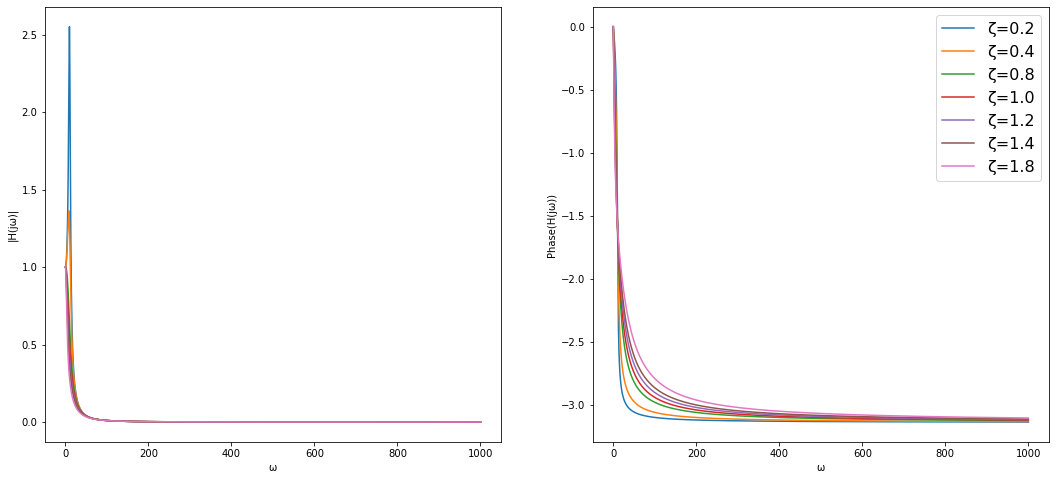

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(18, 8))
ω_n = 10
omega_range = np.linspace(0, 100 * ω_n, 10000)

for ζ in ζ_values:
    frequency_response = compute_frequency_response(ζ, ω_n)
    ax[0].plot(omega_range, np.abs(frequency_response(omega_range)), label=f"ζ={ζ}")
    ax[1].plot(omega_range, np.angle(frequency_response(omega_range)), label=f"ζ={ζ}")  
    
ax[0].set_xlabel("ω")
ax[0].set_ylabel("|H(jω)|")

ax[1].set_xlabel("ω")
ax[1].set_ylabel("Phase(H(jω))")

plt.legend(fontsize=16)

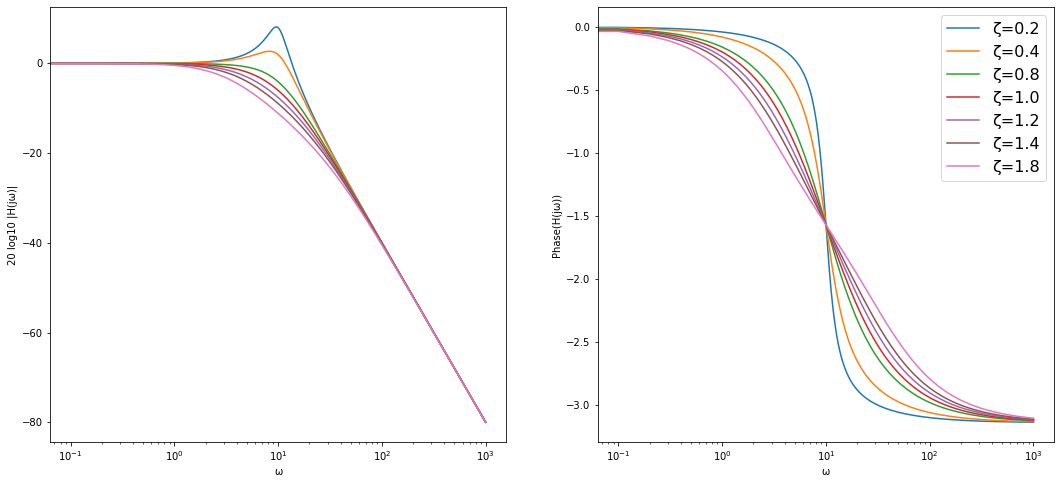

In [9]:

fig, ax = plt.subplots(1, 2, figsize=(18, 8))
ω_n = 10
omega_range = np.linspace(0, 100 * ω_n, 10000)

for ζ in ζ_values:
    frequency_response = compute_frequency_response(ζ, ω_n)
    ax[0].plot(omega_range, 20 * np.log10(np.abs(frequency_response(omega_range))), label=f"ζ={ζ}")
    ax[1].plot(omega_range, np.angle(frequency_response(omega_range)), label=f"ζ={ζ}")  
    
ax[0].set_xlabel("ω")
ax[0].set_ylabel("20 log10 |H(jω)|")
ax[0].set_xscale("log")

ax[1].set_xlabel("ω")
ax[1].set_ylabel("Phase(H(jω))")
ax[1].set_xscale("log")

plt.legend(fontsize=16)